In [ ]:
!pip install -q "numpy<2.3"
!pip install -q terratorch

In [ ]:
import json
import os

import torch
import rasterio
from terratorch.datasets import HLSBands
from terratorch.models import EncoderDecoderFactory
import numpy as np

In [ ]:
# ---------------------------------------------------------------------
# STEP 1: CONNECT TO DRIVE AND LOAD THE SAVED SETTINGS
# ---------------------------------------------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    base_dir = '/content/drive/MyDrive/Prithvi'
except ImportError:
    base_dir = 'Prithvi'

CONFIG_PATH = f'{base_dir}/model/config.json'
CHECKPOINT_PATH = f'{base_dir}/model/best_decoder.pt'
IMAGES_DIR = f'{base_dir}/chips/images'
MASKS_DIR = f'{base_dir}/chips/masks'
OUT_DIR = f'{base_dir}/model'

if not os.path.exists(CONFIG_PATH):
    raise FileNotFoundError(
        f'{CONFIG_PATH} not found. Run save_run_config.py once, in your training '
        f'notebook, then come back here.')
if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(f'{CHECKPOINT_PATH} not found - run train_model.py first.')

with open(CONFIG_PATH) as f:
    config = json.load(f)
print('Settings loaded for this run:')
print(json.dumps(config, indent=2))

VAL_BOXES = config['val_boxes']
NUM_CLASSES = config['num_classes']
IGNORE_INDEX = config['ignore_index']
PRITHVI_VERSION = config['prithvi_version']
ADD_TIME_AXIS = config['add_time_axis']
HEAD_DROPOUT = config['head_dropout']

CLASS_LABELS = ['other', 'raised bog', 'cutover bog', 'grassland']
CLASS_COLORS = ['#D9D9D9', '#8B4513', '#E41A1C', '#4DAF4A']   # grey, brown, red, green

# Prithvi's own published per-band scaling numbers - same two versions as build_dataset.py
STATS = {
    'EO-1.0-100M': {'mean': [775.229, 1080.993, 1228.586, 2497.202, 2204.214, 1610.832],
                    'std':  [1281.526, 1270.030, 1399.480, 1368.345, 1291.676, 1154.506]},
    'EO-2.0':      {'mean': [1087.0, 1342.0, 1433.0, 2734.0, 1958.0, 1363.0],
                    'std':  [2248.0, 2179.0, 2178.0, 1850.0, 1242.0, 1049.0]},
}
BAND_MEAN = np.array(STATS[PRITHVI_VERSION]['mean'], dtype='float32').reshape(6, 1, 1)
BAND_STD = np.array(STATS[PRITHVI_VERSION]['std'], dtype='float32').reshape(6, 1, 1)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'\nEvaluating on: {device}')


Mounted at /content/drive
Settings loaded for this run:
{
  "train_boxes": [
    1,
    2,
    3,
    4,
    5,
    6,
    7
  ],
  "val_boxes": [
    8,
    9
  ],
  "num_classes": 4,
  "ignore_index": 255,
  "prithvi_version": "EO-2.0",
  "add_time_axis": true,
  "head_dropout": 0.1
}

Evaluating on: cuda


In [ ]:
# ---------------------------------------------------------------------
# STEP 2: REBUILD THE VALIDATION CHIPS (SAME LOGIC AS build_dataset.py)
# ---------------------------------------------------------------------
def load_chip(box):
    tag = f'box{box:02d}'
    img_path, mask_path = f'{IMAGES_DIR}/{tag}_image.tif', f'{MASKS_DIR}/{tag}_mask.tif'
    if not (os.path.exists(img_path) and os.path.exists(mask_path)):
        raise FileNotFoundError(f'Missing {img_path} or {mask_path} - was box {box} pulled?')

    with rasterio.open(img_path) as src:
        image = src.read().astype('float32')                  # (6, 224, 224)
        nodata = src.nodata
    with rasterio.open(mask_path) as src:
        mask = src.read(1).astype('int64')                    # (224, 224)

    # "no data" can be written three ways: empty (NaN), a special number, or zeros
    missing = np.isnan(image).any(axis=0)
    if nodata is not None and not np.isnan(nodata) and nodata != 0:
        missing |= (image == nodata).any(axis=0)
    missing |= (image == 0).all(axis=0)

    # some sources give 0-1 reflectance, others 0-10,000 - detect which, same as build_dataset.py
    valid = image[:, ~missing]
    median = float(np.median(valid)) if valid.size else float('nan')
    scale = 10000.0 if (valid.size and median < 10) else 1.0
    image = image * scale

    image = np.where(missing[None], BAND_MEAN, image)          # neutral filler at empty pixels
    mask[missing] = IGNORE_INDEX                                # ... and "ignore" in the mask
    image = ((image - BAND_MEAN) / BAND_STD).astype('float32')  # scale the way Prithvi was trained
    return image, mask


val_images, val_masks = [], []
for box in VAL_BOXES:
    img, msk = load_chip(box)
    val_images.append(img)
    val_masks.append(msk)
print(f'\nLoaded {len(val_images)} held-back validation chips: {VAL_BOXES}')



Loaded 2 held-back validation chips: [8, 9]


In [ ]:
# ---------------------------------------------------------------------
# STEP 3: REBUILD THE MODEL AND LOAD THE TRAINED WEIGHTS
# ---------------------------------------------------------------------
factory = EncoderDecoderFactory()
model = factory.build_model(
    task="segmentation",
    backbone="prithvi_eo_v2_300",
    backbone_pretrained=True,       # Prithvi's own weights, downloaded fresh here
    backbone_bands=[HLSBands.BLUE, HLSBands.GREEN, HLSBands.RED,
                    HLSBands.NIR_NARROW, HLSBands.SWIR_1, HLSBands.SWIR_2],
    backbone_num_frames=1,
    necks=[
        {"name": "SelectIndices", "indices": [5, 11, 17, 23]},
        {"name": "ReshapeTokensToImage"},
        {"name": "LearnedInterpolateToPyramidal"},
    ],
    decoder="UNetDecoder",
    decoder_channels=[512, 256, 128, 64],
    num_classes=NUM_CLASSES,
    head_dropout=HEAD_DROPOUT,
)
model.freeze_encoder()
model.to(device)

trained_state = torch.load(CHECKPOINT_PATH, map_location=device)
missing_keys, unexpected_keys = model.load_state_dict(trained_state, strict=False)
# everything NOT restored should be exactly the (untouched, pretrained) encoder -
# if anything else is missing, the rebuilt architecture doesn't match the checkpoint
bad = [k for k in missing_keys if not k.startswith('encoder.')]
if bad or unexpected_keys:
    raise RuntimeError(
        f'Checkpoint does not match this architecture - unexpected: {unexpected_keys[:5]}, '
        f'unrestored non-encoder weights: {bad[:5]}. Did config.json come from this same '
        f'checkpoint?')
model.eval()
print(f'\nLoaded trained weights from: {CHECKPOINT_PATH}')
print(f'({len(trained_state)} trained tensors restored on top of pretrained Prithvi)')

Prithvi_EO_V2_300M.pt: reconstructing file:   0%|          |  0.00B / 1.33GB            

Prithvi_EO_V2_300M.pt: downloading bytes:           |  0.00B            


Loaded trained weights from: /content/drive/MyDrive/Prithvi/model/best_decoder.pt
(61 trained tensors restored on top of pretrained Prithvi)


In [ ]:
# ---------------------------------------------------------------------
# STEP 4: EVALUATE - CONFUSION MATRIX, THEN IOU / PRECISION / RECALL / F1
# ---------------------------------------------------------------------
confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype='int64')   # rows = true, columns = predicted
predictions = []    # kept for the pictures in step 5: (raw 6-band image, true mask, predicted mask)

with torch.no_grad():
    for img, mask_np in zip(val_images, val_masks):
        image = torch.from_numpy(img)
        if ADD_TIME_AXIS:
            image = image.unsqueeze(1)                          # (bands, H, W) -> (bands, 1, H, W)
        logits = model(image.unsqueeze(0).to(device)).output     # add the batch dimension
        pred = logits.argmax(dim=1).squeeze(0).cpu().numpy()

        valid = mask_np != IGNORE_INDEX
        for t in range(NUM_CLASSES):
            true_t = (mask_np == t) & valid
            for p in range(NUM_CLASSES):
                confusion[t, p] += int((true_t & (pred == p)).sum())

        predictions.append((img * BAND_STD + BAND_MEAN, mask_np, pred))   # undo scaling, for the picture

print(f'\nEvaluated on {len(val_images)} held-back chips '
     f'({confusion.sum():,} pixels, after dropping any "ignore" pixels)\n')

print('Confusion matrix (rows = true class, columns = what the model guessed):')
print(' ' * 16 + ''.join(f'{n:>14s}' for n in CLASS_LABELS))
for t, name in enumerate(CLASS_LABELS):
    print(f'  true {name:11s}' + ''.join(f'{confusion[t, p]:>14,}' for p in range(NUM_CLASSES)))

tp = np.diag(confusion).astype('float64')
fp = confusion.sum(axis=0) - tp
fn = confusion.sum(axis=1) - tp
support = confusion.sum(axis=1)

iou = np.divide(tp, tp + fp + fn, out=np.zeros(NUM_CLASSES), where=(tp + fp + fn) > 0)
precision = np.divide(tp, tp + fp, out=np.zeros(NUM_CLASSES), where=(tp + fp) > 0)
recall = np.divide(tp, tp + fn, out=np.zeros(NUM_CLASSES), where=(tp + fn) > 0)
f1 = np.divide(2 * precision * recall, precision + recall,
               out=np.zeros(NUM_CLASSES), where=(precision + recall) > 0)

print(f'\n{"class":14s}{"pixels":>10s}{"IoU":>8s}{"precision":>12s}{"recall":>9s}{"F1":>8s}')
for i, name in enumerate(CLASS_LABELS):
    print(f'{name:14s}{support[i]:>10,}{iou[i]:>8.1%}{precision[i]:>12.1%}{recall[i]:>9.1%}{f1[i]:>8.1%}')

present = support > 0
print(f'\nMean IoU across the {present.sum()} classes actually present in these chips: '
     f'{iou[present].mean():.1%}')
if not present.all():
    absent = [CLASS_LABELS[i] for i in range(NUM_CLASSES) if not present[i]]
    print(f'(not counted: {absent} - no pixels of these in the validation chips at all)')




Evaluated on 2 held-back chips (100,352 pixels, after dropping any "ignore" pixels)

Confusion matrix (rows = true class, columns = what the model guessed):
                         other    raised bog   cutover bog     grassland
  true other              20,285         1,397        11,017        12,778
  true raised bog            138         1,540           576            39
  true cutover bog           991           521         2,092           137
  true grassland           2,543           124         1,449        44,725

class             pixels     IoU   precision   recall      F1
other             45,477   41.3%       84.7%    44.6%   58.4%
raised bog         2,293   35.5%       43.0%    67.2%   52.4%
cutover bog        3,741   12.5%       13.8%    55.9%   22.2%
grassland         48,841   72.4%       77.5%    91.6%   84.0%

Mean IoU across the 4 classes actually present in these chips: 40.4%


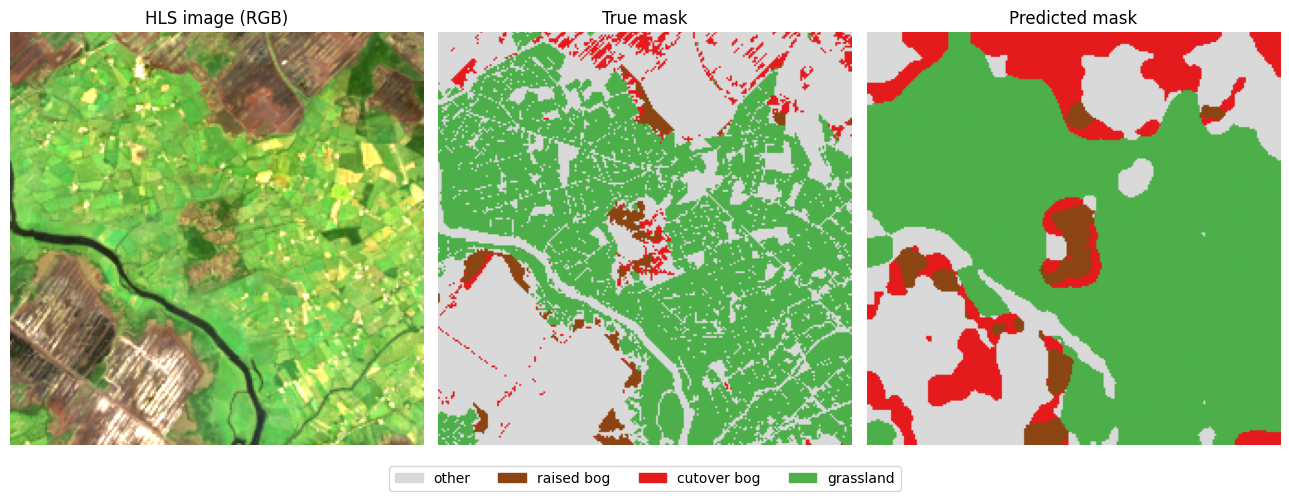

Saved -> /content/drive/MyDrive/Prithvi/model/val_comparison_01.png


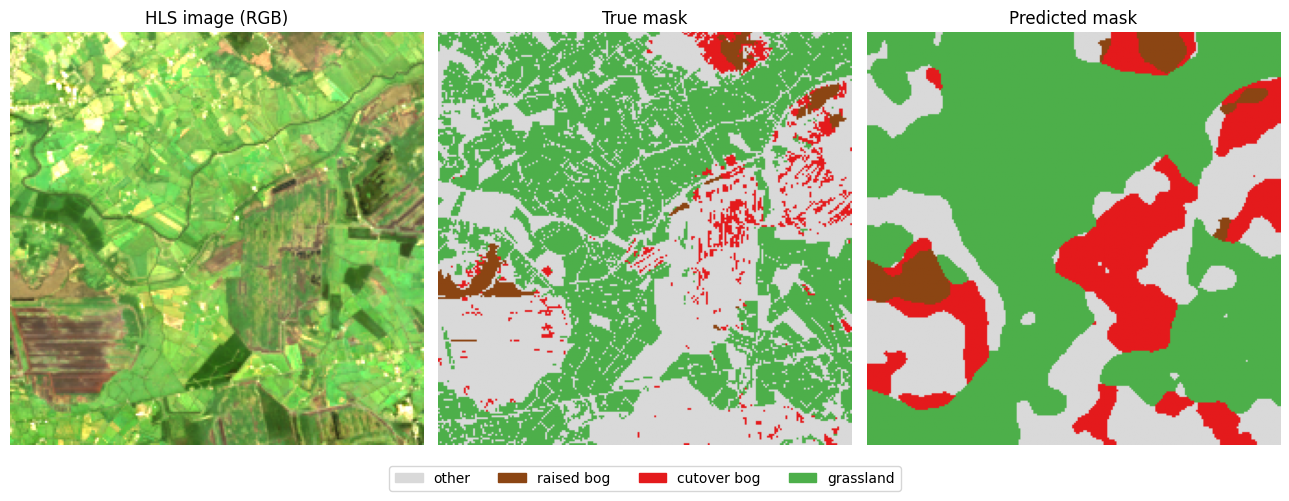

Saved -> /content/drive/MyDrive/Prithvi/model/val_comparison_02.png


In [ ]:
# ---------------------------------------------------------------------
# STEP 5: A PICTURE PER VALIDATION CHIP - IMAGE, TRUE MASK, PREDICTED MASK
# ---------------------------------------------------------------------
os.makedirs(OUT_DIR, exist_ok=True)
try:
    import matplotlib.pyplot as plt
    from matplotlib.colors import ListedColormap

    cmap = ListedColormap(CLASS_COLORS)

    for i, (raw, mask_np, pred) in enumerate(predictions):
        rgb = np.stack([raw[2], raw[1], raw[0]], axis=-1)      # Red, Green, Blue
        bright = np.nanpercentile(rgb, 98)
        rgb = np.clip(rgb / bright, 0, 1) if bright > 0 else np.zeros_like(rgb)

        fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
        axes[0].imshow(rgb)
        axes[0].set_title('HLS image (RGB)')
        axes[1].imshow(mask_np, cmap=cmap, vmin=0, vmax=NUM_CLASSES - 1)
        axes[1].set_title('True mask')
        axes[2].imshow(pred, cmap=cmap, vmin=0, vmax=NUM_CLASSES - 1)
        axes[2].set_title('Predicted mask')
        for ax in axes:
            ax.axis('off')

        handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CLASS_COLORS]
        fig.legend(handles, CLASS_LABELS, loc='lower center', ncol=NUM_CLASSES, bbox_to_anchor=(0.5, -0.04))
        plt.tight_layout()

        out_path = f'{OUT_DIR}/val_comparison_{i + 1:02d}.png'
        plt.savefig(out_path, dpi=120, bbox_inches='tight')
        plt.show()
        print(f'Saved -> {out_path}')
except Exception as e:
    print(f'(Comparison pictures skipped: {e})')
